# California Housing Data: Introduction

## What does one row represent?

Each row in this dataset represents a **census block group in California**, not one individual house or household. The values describe or summarize the people and housing in that geographic area.

## Why are some columns called "median"?

`median_income` and `median_house_value` are area-level statistics. For each block group, households or homes are ordered by income or value, and the middle observation is reported as the median. Therefore, these columns do not give the income or price of a particular household or house, nor do they give one median calculated across the entire dataset.

Other columns describe counts for the area: `total_rooms`, `total_bedrooms`, `population`, and `households`. The dataset also includes the block group's location, housing median age, and ocean proximity.

## Project goal

This project explores the data and builds regression models to predict a block group's **median house value** from its other characteristics. Because `total_bedrooms` has missing entries, missing-value handling will be considered during preparation for modeling.

### Data understanding and inspection

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
house_df = pd.read_csv('../data/raw/housing.csv')
house_df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


### Understand the dataset

In [3]:
house_df.shape

(20640, 10)

In [4]:
house_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [5]:
house_df.dtypes

longitude             float64
latitude              float64
housing_median_age    float64
total_rooms           float64
total_bedrooms        float64
population            float64
households            float64
median_income         float64
median_house_value    float64
ocean_proximity           str
dtype: object

In [6]:
house_df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


### Check for missing values

In [7]:
house_df.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

One of the most important variables in house price prediction, "total_bedrooms", has over 200 missing rows. Because of its importance and the fact that only about 1% of its data is missing, the variable was not dropped.

However, to handle these missing values, we shall impute them with the median. Median is used because the data is skewed, based on the median scores.

In [16]:
#Treat the missing values in the dataset
bedrooms_median = house_df["total_bedrooms"].median()
house_df["total_bedrooms"] = house_df["total_bedrooms"].fillna(bedrooms_median)

### Check for duplicates

In [17]:
house_df["total_bedrooms"].isna().sum()

np.int64(0)

Now it is confirmed that the missing values have been dealt with!

In [ ]:
#Check for duplicates in the dataset
house_df.duplicated().sum()

np.int64(0)

### Check the target variable

In [19]:
house_df.columns

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity'],
      dtype='str')

In [20]:
house_df["median_house_value"].describe()

count     20640.000000
mean     206855.816909
std      115395.615874
min       14999.000000
25%      119600.000000
50%      179700.000000
75%      264725.000000
max      500001.000000
Name: median_house_value, dtype: float64

### Check distributions

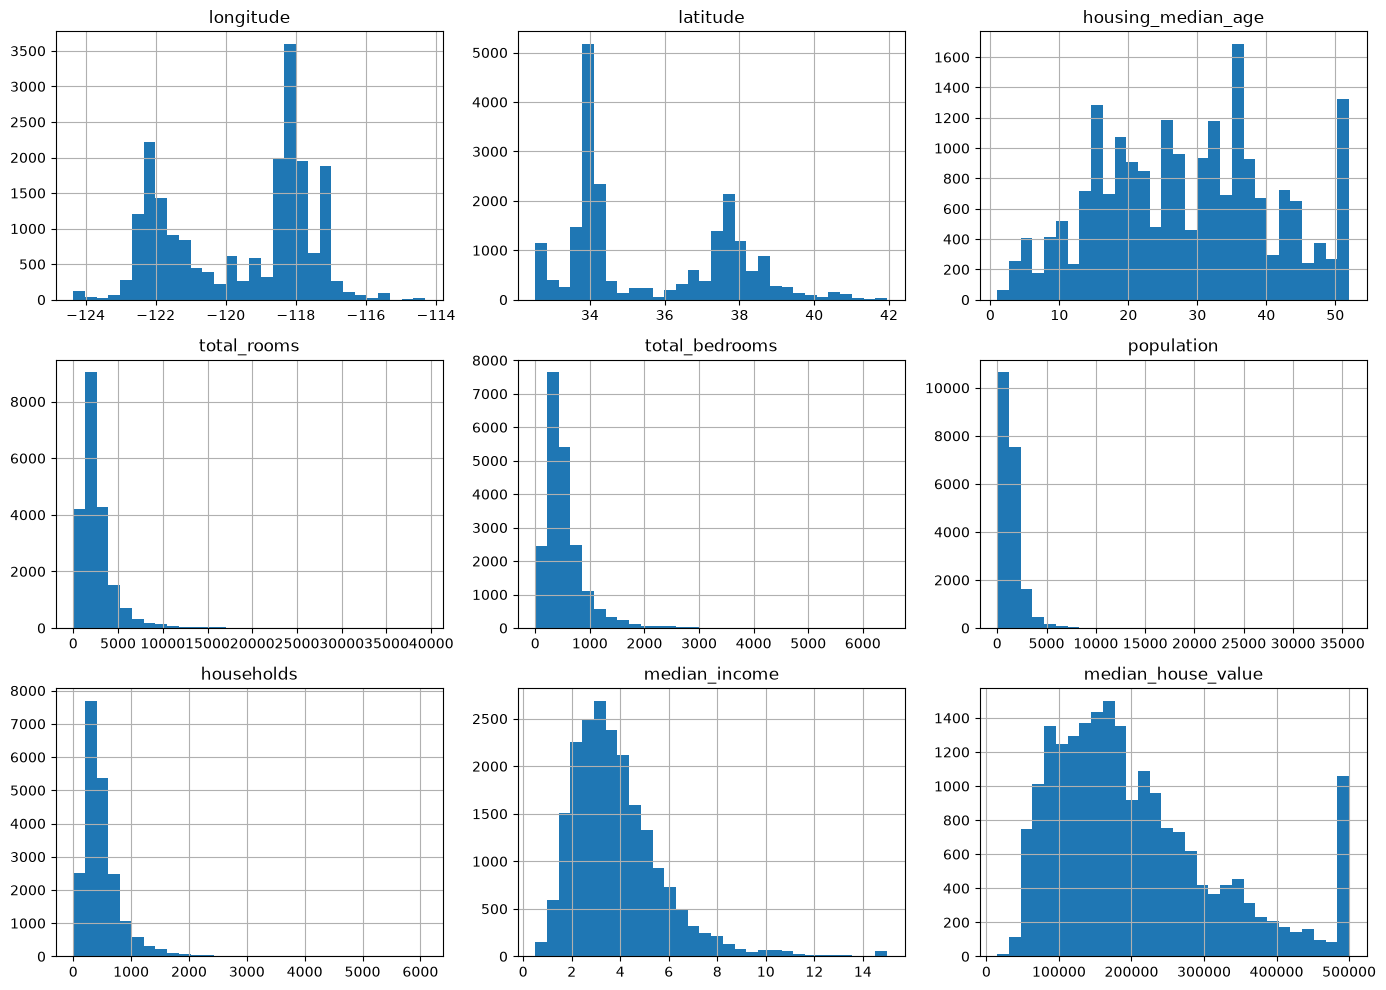

In [21]:
house_df.hist(figsize=(14, 10), bins=30)

plt.tight_layout()
plt.show()

### Correlation analysis

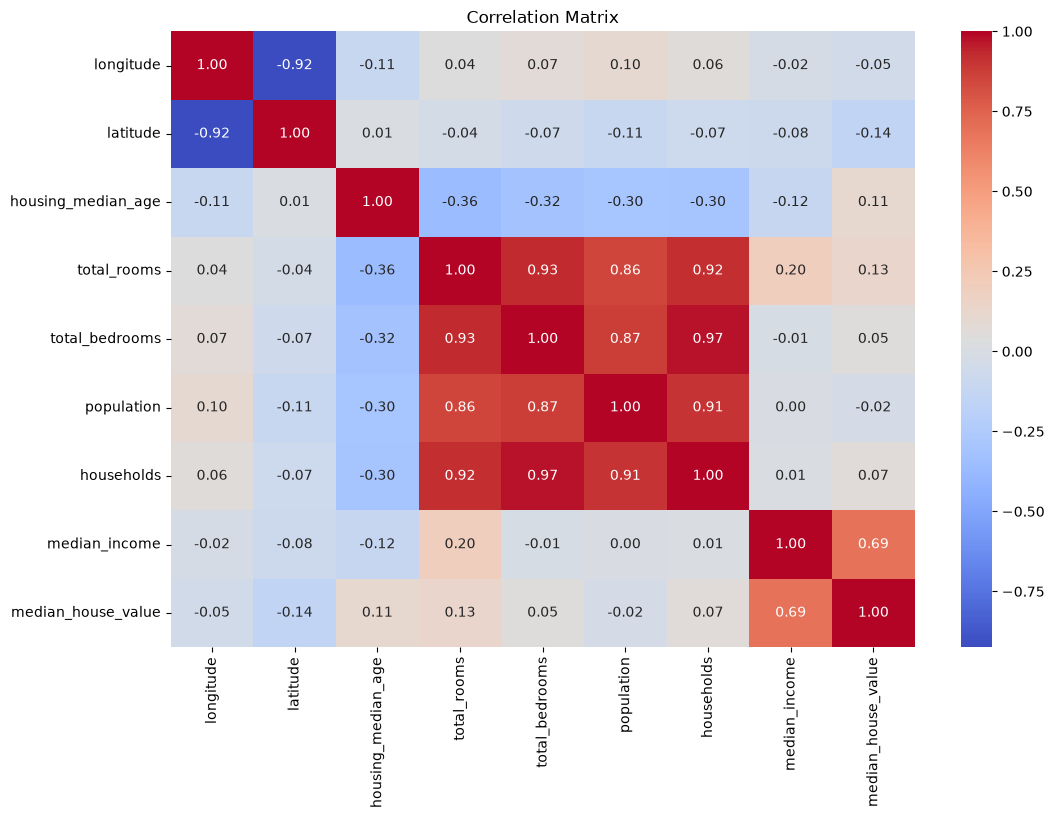

In [23]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    house_df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()

### Check relationships with the target

In [27]:
target_corr = house_df.corr(numeric_only=True)["median_house_value"].sort_values(ascending=False)

target_corr

median_house_value    1.000000
median_income         0.688075
total_rooms           0.134153
housing_median_age    0.105623
households            0.065843
total_bedrooms        0.049457
population           -0.024650
longitude            -0.045967
latitude             -0.144160
Name: median_house_value, dtype: float64

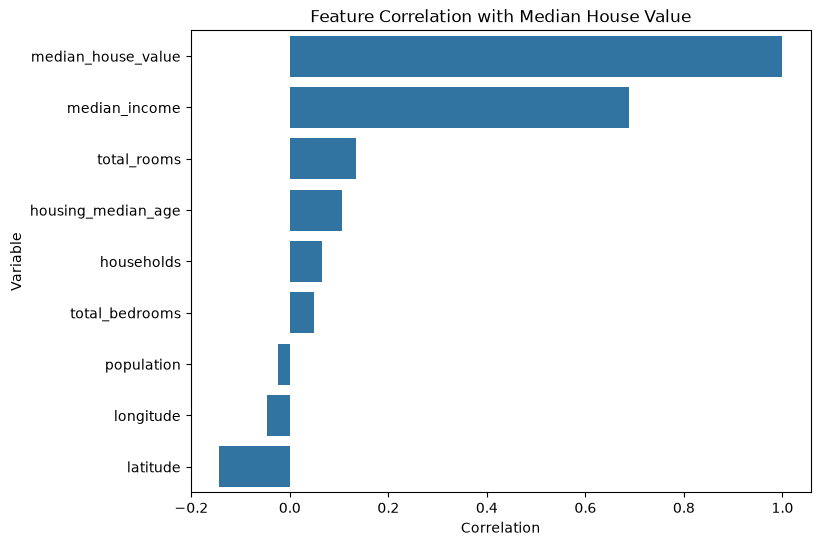

In [28]:
plt.figure(figsize=(8, 6))

sns.barplot(
    x=target_corr.values,
    y=target_corr.index
)

plt.title("Feature Correlation with Median House Value")
plt.xlabel("Correlation")
plt.ylabel("Variable")

plt.show()

## Overall Interpretation

This exploratory analysis covers **20,640 California census block groups**, with 10 columns describing area-level housing, demographic, location, and income characteristics. Each row represents a geographic area rather than an individual home; accordingly, `median_house_value` is the area's median home value and is the target for this project.

### Data quality and preparation

- `total_bedrooms` was the only column with missing data: 207 rows, or about **1%** of the dataset. The missing entries were filled with the column median, preserving the rows and limiting the influence of unusually large counts.
- No duplicate rows were found.
- When preparing data for model evaluation, calculate the imputation median using only the training split, then apply that same value to validation or test data. This prevents information from those held-out sets from leaking into training.

### Target distribution and relationships

`median_house_value` ranges from **$14,999 to $500,001**. Its mean (about **$206,856**) exceeds its median (**$179,700**), showing that high-value observations raise the average above the midpoint. The histograms and descriptive statistics show that feature scales and distributions vary, which informs model preparation.

`median_income` has the strongest positive linear correlation with `median_house_value` (**r ≈ 0.69**). Block groups with higher median incomes are associated with higher median house values. The remaining numeric features have substantially weaker individual linear correlations with the target. `latitude` has a modest negative correlation (**r ≈ -0.14**), while rooms, bedrooms, households, and population each have weak correlations.

These correlations describe association, not cause and effect, and they do not capture non-linear relationships or interactions. The numeric correlation analysis excludes the categorical `ocean_proximity` feature.

### Implications for modeling

`median_house_value` is the prediction target, and `median_income` is the strongest numeric linear correlate in this analysis. Include and evaluate the full set of relevant features rather than selecting predictors from correlation alone. Room, bedroom, and household counts describe related aspects of an area, so assess their redundancy and multicollinearity when fitting regression models. Measure model performance on held-out data using RMSE, MAE, and R²; exploratory patterns alone do not measure predictive performance.